# Chapitre 12 - Cours 1 : le classifieur à vaste marge

Ce premier notebook du chapitre 12 (sections 12.1 à 12.2 du livre) construit pas à pas le
**classifieur à vecteurs de support** (*support vector classifier*) :

1. hyperplans séparateurs et notion de **marge** ;
2. les outils d'optimisation sous contraintes nécessaires : **Lagrangien**, **conditions de
   Karush–Kuhn–Tucker (KKT)**, **dualité** - introduits au niveau Licence ;
3. le cas **séparable** (marge « dure ») ;
4. le cas **non séparable** (marge « souple », variables d'écart, paramètre de coût $C$) ;
5. la résolution numérique du problème dual (algorithme **SMO**) ;
6. l'exemple « mixture » du livre (figure 12.2).

Les noyaux (SVM non linéaires), la perte charnière et la régression sont l'objet du cours 2 ;
les discriminants flexibles (FDA, PDA, MDA) du cours 3.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch12_svm import (SVMClassifier, smo_solve, qp_interior_point, simulate_mixture,
                          mixture_bayes_prob, plot_mixture_boundary)
set_style()

## 1. Hyperplans et distance signée

On dispose de $N$ observations $(x_i, y_i)$ avec $x_i \in \mathbb{R}^p$ et une étiquette
$y_i \in \{-1, +1\}$. Un **hyperplan** de $\mathbb{R}^p$ est un ensemble de la forme

$$\{x : f(x) = x^T\beta + \beta_0 = 0\}, \qquad \beta \in \mathbb{R}^p\setminus\{0\},\ \beta_0\in\mathbb{R}$$

(éq. (12.1) du livre). La règle de classement associée est $G(x) = \mathrm{sign}[f(x)]$
(éq. (12.2)).

**Propriété (distance signée).** Si $\|\beta\| = 1$, la distance euclidienne de $x$ à
l'hyperplan vaut $|f(x)|$, et le signe de $f(x)$ indique de quel côté se trouve $x$.

*Démonstration.* Soit $x_0$ un point de l'hyperplan : $x_0^T\beta = -\beta_0$. Le vecteur
$\beta$ est orthogonal à l'hyperplan (pour deux points $x_0, x_0'$ de l'hyperplan,
$(x_0 - x_0')^T\beta = 0$). La distance de $x$ à l'hyperplan est donc la longueur de la
projection de $x - x_0$ sur la direction unitaire $\beta/\|\beta\|$ :

$$d(x) = \frac{(x - x_0)^T\beta}{\|\beta\|} = \frac{x^T\beta + \beta_0}{\|\beta\|} = \frac{f(x)}{\|\beta\|}.$$

Avec $\|\beta\| = 1$ on obtient $d(x) = f(x)$. $\square$

> **À retenir.** Pour $\beta$ quelconque, $f(x)/\|\beta\|$ est la distance signée de $x$ à
> l'hyperplan. Un point est bien classé si et seulement si $y_i f(x_i) > 0$.

Construisons un petit jeu de données **séparable** en dimension 2 pour illustrer. Une infinité
d'hyperplans séparent parfaitement les deux classes : lequel choisir ?

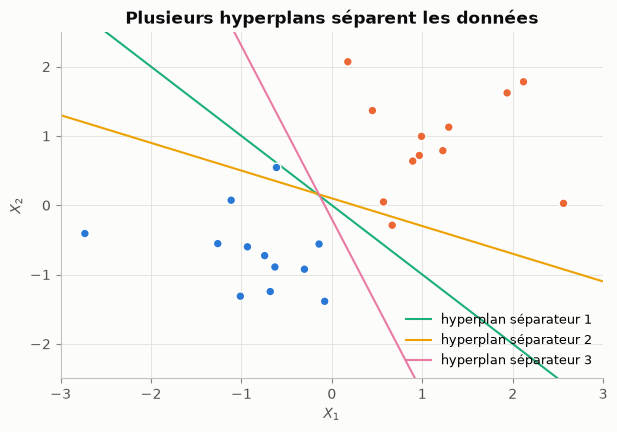

In [2]:
rng = np.random.RandomState(0)
n = 12
Xs = np.vstack([rng.randn(n, 2) * 0.6 + [-1.2, -0.8], rng.randn(n, 2) * 0.6 + [1.2, 0.9]])
ys = np.r_[-np.ones(n), np.ones(n)]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(Xs[:, 0], Xs[:, 1], c=(ys > 0), cmap=TWO_CLASS, s=40, edgecolor="white", zorder=3)
t = np.linspace(-3, 3, 10)
for k, (a, b0) in enumerate([(-1.0, 0.0), (-0.4, 0.1), (-2.5, -0.2)]):
    ax.plot(t, a * t + b0, color=COLORS[2 + k], lw=1.5, label="hyperplan séparateur %d" % (k + 1))
ax.set_xlim(-3, 3); ax.set_ylim(-2.5, 2.5)
ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$")
ax.set_title("Plusieurs hyperplans séparent les données")
ax.legend(loc="lower right")
plt.show()

## 2. Le problème de la marge maximale

Si les classes sont séparables, il existe $f$ affine avec $y_i f(x_i) > 0$ pour tout $i$.
L'idée est de choisir l'hyperplan qui maximise la **marge** $M$, c'est-à-dire la distance
minimale entre l'hyperplan et les points d'apprentissage (éq. (12.3) du livre) :

$$\max_{\beta, \beta_0,\ \|\beta\| = 1} M \quad \text{sous les contraintes} \quad y_i(x_i^T\beta + \beta_0) \ge M,\quad i = 1, \dots, N.$$

La bande de part et d'autre de l'hyperplan a une largeur totale $2M$.

**Reformulation (éq. (12.4)).** La contrainte $\|\beta\| = 1$ est gênante (elle n'est pas
convexe). On s'en débarrasse en remarquant que :

* pour $\beta$ quelconque, la contrainte $y_i(x_i^T\beta + \beta_0)/\|\beta\| \ge M$
  exprime la même chose (distance signée) ;
* le couple $(\beta, \beta_0)$ n'est défini qu'à un facteur positif près : on peut donc
  **choisir l'échelle** $\|\beta\| = 1/M$.

Les contraintes deviennent $y_i(x_i^T\beta + \beta_0) \ge 1$, et maximiser $M = 1/\|\beta\|$
revient à minimiser $\|\beta\|$, ou de façon équivalente $\tfrac12\|\beta\|^2$ (plus commode
à dériver) :

$$\min_{\beta,\beta_0} \tfrac12\|\beta\|^2 \quad\text{sous}\quad y_i(x_i^T\beta + \beta_0) \ge 1,\quad i = 1,\dots,N.$$

C'est un problème **quadratique convexe** (critère quadratique, contraintes affines). Pour
le résoudre et surtout pour comprendre la structure de sa solution, nous avons besoin des
multiplicateurs de Lagrange.

## 3. Boîte à outils : Lagrangien, conditions KKT, dualité

### 3.1 Rappel : extremum lié avec une contrainte d'égalité

Pour minimiser $F(x)$ sous la contrainte $h(x) = 0$ ($F, h$ dérivables), on sait (cours de
calcul différentiel) qu'en un extremum lié régulier, les gradients sont colinéaires :
$\nabla F(x^\star) = \nu\, \nabla h(x^\star)$ pour un réel $\nu$, appelé **multiplicateur de
Lagrange**. De manière équivalente, $x^\star$ est un point critique du **Lagrangien**

$$\mathcal{L}(x, \nu) = F(x) - \nu\, h(x).$$

> **Intuition.** Si $\nabla F$ avait une composante tangente à la contrainte, on pourrait
> glisser le long de la contrainte en faisant diminuer $F$.

### 3.2 Contraintes d'inégalité : un exemple en dimension 1

Considérons $\min_x \tfrac12 x^2$ sous la contrainte $g(x) = x - c \ge 0$.

* Si $c \le 0$, le minimum libre $x = 0$ satisfait la contrainte : elle est **inactive** et
  ne joue aucun rôle.
* Si $c > 0$, le minimum est atteint au bord, $x^\star = c$ : la contrainte est **active**.
  En ce point, la dérivée $F'(c) = c$ est positive : diminuer $x$ ferait baisser $F$ mais
  sortirait de l'ensemble admissible.

On introduit le Lagrangien $\mathcal{L}(x, \alpha) = \tfrac12 x^2 - \alpha (x - c)$ avec
$\alpha \ge 0$. Les deux cas sont résumés par les conditions :

$$x^\star - \alpha = 0,\qquad \alpha \ge 0,\qquad x^\star - c \ge 0,\qquad \alpha\,(x^\star - c) = 0.$$

La dernière, dite de **complémentarité**, dit que *soit* le multiplicateur est nul
(contrainte inactive), *soit* la contrainte est saturée. On trouve $\alpha = \max(c, 0)$ et
$x^\star = \max(c, 0)$.

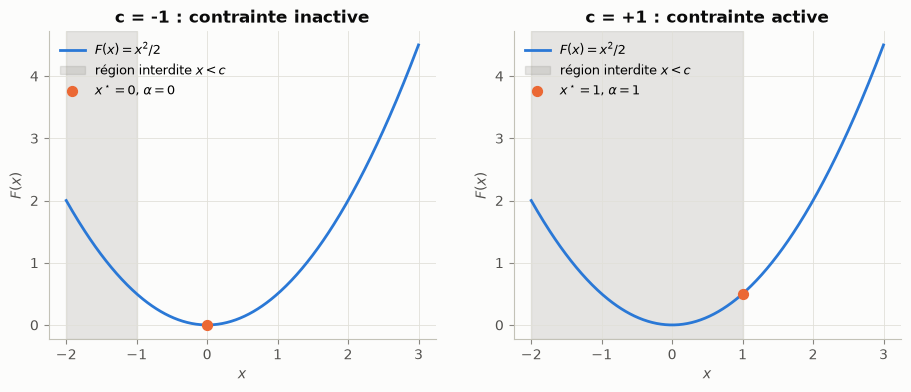

In [3]:
x = np.linspace(-2, 3, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, c in zip(axes, [-1.0, 1.0]):
    ax.plot(x, 0.5 * x ** 2, color=BLUE, label=r"$F(x) = x^2/2$")
    ax.axvspan(-2, c, color=GRAY, alpha=0.2, label="région interdite $x < c$")
    xs = max(c, 0)
    ax.scatter([xs], [0.5 * xs ** 2], color=ORANGE, zorder=3, s=50,
               label=r"$x^\star = %.0f$, $\alpha = %.0f$" % (xs, max(c, 0)))
    ax.set_xlabel("$x$"); ax.set_ylabel("$F(x)$")
    ax.set_title("c = %+.0f : contrainte %s" % (c, "inactive" if c <= 0 else "active"))
    ax.legend(loc="upper left")
plt.show()

### 3.3 Conditions de Karush–Kuhn–Tucker (KKT)

Plus généralement, considérons le problème

$$\min_{x\in\mathbb{R}^n} F(x) \quad \text{sous}\quad g_i(x) \ge 0,\ i = 1, \dots, m,$$

avec $F$ **convexe** et les $g_i$ **affines** (c'est exactement notre cadre). Le Lagrangien
est $\mathcal{L}(x, \alpha) = F(x) - \sum_i \alpha_i g_i(x)$, avec $\alpha_i \ge 0$.

**Théorème (admis).** Sous ces hypothèses, $x^\star$ est solution si et seulement s'il
existe $\alpha^\star \in \mathbb{R}^m$ tel que :

1. *stationnarité* : $\nabla F(x^\star) = \sum_i \alpha^\star_i \nabla g_i(x^\star)$ ;
2. *admissibilité* : $g_i(x^\star) \ge 0$ ;
3. *positivité des multiplicateurs* : $\alpha^\star_i \ge 0$ ;
4. *complémentarité* : $\alpha^\star_i\, g_i(x^\star) = 0$ pour tout $i$.

Ce sont les conditions KKT. La condition 4 généralise l'exemple précédent : un
multiplicateur non nul signale une contrainte saturée.

### 3.4 Dualité

On définit la **fonction duale** $D(\alpha) = \min_x \mathcal{L}(x, \alpha)$ pour
$\alpha \ge 0$.

**Dualité faible.** Pour tout $x$ admissible et tout $\alpha \ge 0$, $D(\alpha) \le F(x)$.

*Preuve.* $D(\alpha) \le \mathcal{L}(x, \alpha) = F(x) - \sum_i \alpha_i g_i(x) \le F(x)$,
car chaque terme $\alpha_i g_i(x)$ est positif ($\alpha_i \ge 0$ et $g_i(x) \ge 0$). $\square$

**Dualité forte (admise).** Dans le cadre convexe à contraintes affines, si le problème a une
solution, $\max_{\alpha \ge 0} D(\alpha) = \min_{x \text{ admissible}} F(x)$ : on peut
résoudre le **problème dual** à la place du primal.

Vérifions-le sur l'exemple 1D avec $c = 1$ : $\min_x \mathcal{L} $ est atteint en $x = \alpha$,
donc $D(\alpha) = \tfrac12\alpha^2 - \alpha(\alpha - 1) = \alpha - \tfrac12\alpha^2$, maximal en
$\alpha = 1$ où il vaut $\tfrac12 = F(1)$.

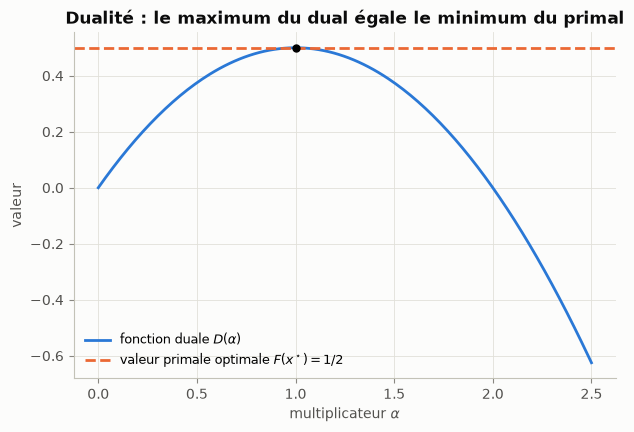

In [4]:
alpha = np.linspace(0, 2.5, 200)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(alpha, alpha - 0.5 * alpha ** 2, color=BLUE, label=r"fonction duale $D(\alpha)$")
ax.axhline(0.5, color=ORANGE, ls="--", label=r"valeur primale optimale $F(x^\star) = 1/2$")
ax.scatter([1], [0.5], color="k", zorder=3)
ax.set_xlabel(r"multiplicateur $\alpha$"); ax.set_ylabel("valeur")
ax.set_title("Dualité : le maximum du dual égale le minimum du primal")
ax.legend()
plt.show()

## 4. Le cas séparable : marge dure

Appliquons ces outils à $\min \tfrac12\|\beta\|^2$ sous $y_i(x_i^T\beta + \beta_0) \ge 1$.
Le Lagrangien est

$$\mathcal{L}(\beta, \beta_0, \alpha) = \tfrac12\|\beta\|^2 - \sum_{i=1}^N \alpha_i\left[y_i(x_i^T\beta + \beta_0) - 1\right],\qquad \alpha_i \ge 0.$$

**Stationnarité.** On dérive par rapport à $\beta$ (gradient) et à $\beta_0$ :

$$\nabla_\beta \mathcal{L} = \beta - \sum_i \alpha_i y_i x_i = 0 \;\Rightarrow\; \beta = \sum_i \alpha_i y_i x_i,
\qquad \frac{\partial \mathcal{L}}{\partial\beta_0} = -\sum_i \alpha_i y_i = 0.$$

**Problème dual.** On remplace $\beta$ par $\sum_i\alpha_i y_i x_i$ dans $\mathcal{L}$, en
utilisant $\sum_i \alpha_i y_i = 0$ (le terme en $\beta_0$ disparaît) :

$$\begin{aligned}
D(\alpha) &= \tfrac12 \Big\|\sum_i \alpha_i y_i x_i\Big\|^2 - \sum_i \alpha_i y_i x_i^T \sum_{i'} \alpha_{i'} y_{i'} x_{i'} + \sum_i \alpha_i \\
&= \sum_i \alpha_i - \tfrac12 \sum_{i}\sum_{i'} \alpha_i\alpha_{i'} y_i y_{i'}\, x_i^T x_{i'} .
\end{aligned}$$

On maximise $D$ sous $\alpha_i \ge 0$ et $\sum_i \alpha_i y_i = 0$.

**Complémentarité.** $\alpha_i [y_i(x_i^T\beta + \beta_0) - 1] = 0$ : seuls les points situés
**exactement sur le bord de la marge** ont $\alpha_i > 0$. Ce sont les **vecteurs de support** :
$\beta$ ne dépend que d'eux.

Résolvons numériquement le dual sur nos données séparables. Le module `esl.ch12_svm`
fournit `SVMClassifier` ; un coût $C$ très grand (voir section 5) reproduit la marge dure.

In [5]:
svm_hard = SVMClassifier(C=1e6, kernel="linear").fit(Xs, ys)
beta, beta0 = svm_hard.coef_, svm_hard.b_
print("beta =", beta.round(4), " beta0 = %.4f" % beta0)
print("marge M = 1/||beta|| = %.4f" % (1 / np.linalg.norm(beta)))
print("vecteurs de support :", svm_hard.support_, " alpha =", svm_hard.alpha_[svm_hard.support_].round(4))

beta = [2.2223 0.7457]  beta0 = -0.2679
marge M = 1/||beta|| = 0.4266
vecteurs de support : [ 0 16]  alpha = [2.7473 2.7473]


Vérifions les conditions KKT : admissibilité ($y_i f(x_i) \ge 1$), égalité
$\sum_i\alpha_i y_i = 0$, reconstruction de $\beta$ et complémentarité.

In [6]:
f_s = Xs @ beta + beta0
print("min y_i f(x_i)                 = %.6f" % (ys * f_s).min())
print("sum alpha_i y_i                = %.2e" % (svm_hard.alpha_ @ ys))
print("||beta - sum alpha_i y_i x_i|| = %.2e" % np.linalg.norm(beta - (svm_hard.alpha_ * ys) @ Xs))
print("max |alpha_i (y_i f_i - 1)|    = %.2e" % np.abs(svm_hard.alpha_ * (ys * f_s - 1)).max())
print("y_i f(x_i) des vecteurs de support :", (ys * f_s)[svm_hard.support_].round(5))

min y_i f(x_i)                 = 1.000000
sum alpha_i y_i                = -4.96e-16
||beta - sum alpha_i y_i x_i|| = 0.00e+00
max |alpha_i (y_i f_i - 1)|    = 3.10e-11
y_i f(x_i) des vecteurs de support : [1. 1.]


Figure dans l'esprit du panneau gauche de la figure 12.1 : l'hyperplan optimal, les bords de
la marge $f(x) = \pm 1$, et les vecteurs de support (entourés), tous sur la marge.

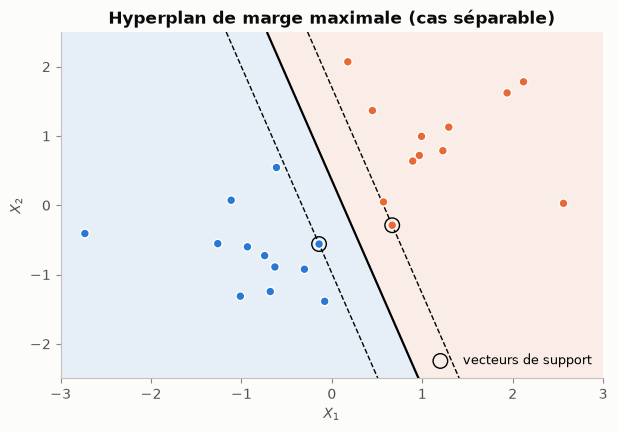

In [7]:
def plot_linear_svm(ax, X, y, svm, lims=(-3, 3, -2.5, 2.5), title=""):
    """Trace la frontière d'un SVM linéaire, ses marges et ses vecteurs de support."""
    xx, yy = np.meshgrid(np.linspace(lims[0], lims[1], 200), np.linspace(lims[2], lims[3], 200))
    F = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, (F > 0).astype(float), levels=[-0.5, 0.5, 1.5], colors=[BLUE, ORANGE], alpha=0.1)
    ax.contour(xx, yy, F, levels=[0], colors="k", linewidths=1.6)
    ax.contour(xx, yy, F, levels=[-1, 1], colors="k", linewidths=1, linestyles="--")
    ax.scatter(X[:, 0], X[:, 1], c=(y > 0), cmap=TWO_CLASS, s=40, edgecolor="white", zorder=3)
    sv = svm.support_
    ax.scatter(X[sv, 0], X[sv, 1], s=110, facecolor="none", edgecolor="k", lw=1, zorder=4,
               label="vecteurs de support")
    ax.set_xlim(lims[:2]); ax.set_ylim(lims[2:])
    ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$"); ax.set_title(title); ax.grid(False)
    ax.legend(loc="lower right")

fig, ax = plt.subplots(figsize=(7, 4.5))
plot_linear_svm(ax, Xs, ys, svm_hard, title="Hyperplan de marge maximale (cas séparable)")
plt.show()

> **À retenir.** L'hyperplan optimal ne dépend que d'une poignée de points (les vecteurs de
> support). Déplacer un point éloigné de la marge, sans franchir celle-ci, ne change rien à
> la solution - contrairement à la LDA, qui dépend de toutes les observations via les
> moyennes et covariances.

## 5. Le cas non séparable : marge souple

Quand les classes se chevauchent, aucune solution ne vérifie toutes les contraintes. On
autorise certains points à franchir leur marge grâce à des **variables d'écart** (*slack
variables*) $\xi_i \ge 0$. Le livre discute deux variantes : $y_i f(x_i) \ge M - \xi_i$
(éq. (12.5), distance absolue, problème non convexe) et

$$y_i(x_i^T\beta + \beta_0) \ge M(1 - \xi_i) \qquad \text{(éq. (12.6), distance relative)},$$

avec $\sum_i\xi_i \le$ constante. La seconde donne un problème convexe ; c'est la forme
standard.

**Interprétation de $\xi_i$.** $\xi_i$ mesure de combien (en proportion de la marge) le point
$i$ est du mauvais côté de sa marge :

* $\xi_i = 0$ : le point est du bon côté de sa marge ;
* $0 < \xi_i \le 1$ : il est dans la bande mais bien classé ;
* $\xi_i > 1$ : il est **mal classé**.

Borner $\sum_i \xi_i$ par $K$ borne donc le nombre d'erreurs d'apprentissage par $K$.

Comme au §2, on pose $M = 1/\|\beta\|$ ; on obtient la forme (12.7) puis, en remplaçant la
contrainte sur $\sum\xi_i$ par une pénalité de **coût** $C$, la forme (12.8) :

$$\min_{\beta, \beta_0, \xi}\ \tfrac12\|\beta\|^2 + C\sum_{i=1}^N \xi_i \quad\text{sous}\quad \xi_i \ge 0,\ \ y_i(x_i^T\beta + \beta_0) \ge 1 - \xi_i.$$

Le cas séparable correspond à $C = \infty$.

### 5.1 Lagrangien et dual (éq. (12.9)–(12.13))

Deux familles de contraintes, donc deux familles de multiplicateurs $\alpha_i \ge 0$ et
$\mu_i \ge 0$ :

$$L_P = \tfrac12\|\beta\|^2 + C\sum_i\xi_i - \sum_i \alpha_i\left[y_i(x_i^T\beta + \beta_0) - (1 - \xi_i)\right] - \sum_i\mu_i\xi_i .$$

On annule les dérivées par rapport à $\beta$, $\beta_0$ et chaque $\xi_i$ :

$$\beta = \sum_i\alpha_i y_i x_i \ \ (12.10),\qquad 0 = \sum_i \alpha_i y_i \ \ (12.11),\qquad \alpha_i = C - \mu_i \ \ (12.12).$$

En substituant dans $L_P$ : les termes en $\xi_i$ se regroupent en
$\sum_i \xi_i (C - \alpha_i - \mu_i) = 0$ par (12.12) ; le terme en $\beta_0$ disparaît par
(12.11) ; il reste exactement la même expression qu'au §4 :

$$L_D = \sum_i\alpha_i - \tfrac12\sum_i\sum_{i'}\alpha_i\alpha_{i'}y_iy_{i'}\,x_i^Tx_{i'} \qquad (12.13).$$

La seule différence est la contrainte : comme $\mu_i = C - \alpha_i \ge 0$, on a
$0 \le \alpha_i \le C$ (contrainte de « boîte »), en plus de $\sum_i\alpha_iy_i = 0$.

### 5.2 Conditions KKT et les trois catégories de points

En plus de (12.10)–(12.12), les conditions KKT comprennent (éq. (12.14)–(12.16)) :

$$\alpha_i\left[y_i f(x_i) - (1-\xi_i)\right] = 0,\qquad \mu_i\xi_i = 0,\qquad y_if(x_i) - (1 - \xi_i) \ge 0.$$

On en déduit la classification des points :

| situation | $\alpha_i$ | $\xi_i$ | $y_i f(x_i)$ |
|---|---|---|---|
| hors de la marge, bien classé | $0$ | $0$ | $\ge 1$ |
| exactement sur la marge | $\in\,]0, C[$ | $0$ | $=1$ |
| dans la marge ou mal classé | $C$ | $>0$ | $<1$ |

(Si $0<\alpha_i<C$ alors $\mu_i = C-\alpha_i > 0$ donc $\xi_i = 0$ et, par complémentarité,
$y_if(x_i) = 1$.) Les points avec $0 < \alpha_i < C$ permettent de calculer $\beta_0$ :
$\beta_0 = y_i - x_i^T\beta$ ; on fait la moyenne sur tous ces points pour la stabilité
numérique.

Illustrons sur des données qui se chevauchent (panneau droit de la figure 12.1).

In [8]:
rng = np.random.RandomState(1)
Xo = np.vstack([rng.randn(n, 2) * 0.8 + [-0.7, -0.5], rng.randn(n, 2) * 0.8 + [0.7, 0.6]])
yo = ys.copy()
svm_soft = SVMClassifier(C=1.0, kernel="linear").fit(Xo, yo)
fo = svm_soft.decision_function(Xo)
xi = np.maximum(0, 1 - yo * fo)
cat = np.where(svm_soft.alpha_ < 1e-5, "alpha=0", np.where(svm_soft.alpha_ > 1 - 1e-5, "alpha=C", "0<alpha<C"))
for c in ["alpha=0", "0<alpha<C", "alpha=C"]:
    m_ = cat == c
    print("%-10s : %2d points, y f(x) dans [%.3f, %.3f], xi max = %.3f"
          % (c, m_.sum(), (yo * fo)[m_].min(), (yo * fo)[m_].max(), xi[m_].max()))

alpha=0    : 15 points, y f(x) dans [1.300, 5.537], xi max = 0.000
0<alpha<C  :  2 points, y f(x) dans [1.000, 1.000], xi max = 0.000
alpha=C    :  7 points, y f(x) dans [-0.046, 0.915], xi max = 1.046


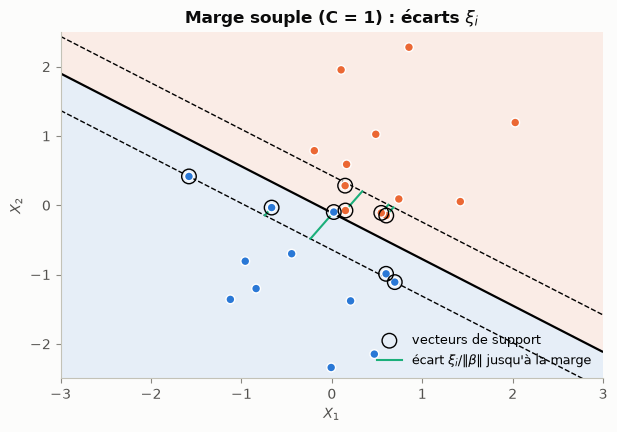

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
plot_linear_svm(ax, Xo, yo, svm_soft, title="Marge souple (C = 1) : écarts $\\xi_i$")
bo = svm_soft.coef_
for k, i in enumerate(np.flatnonzero(xi > 1e-6)):
    end = Xo[i] + yo[i] * bo * xi[i] / (bo @ bo)   # point de la marge correspondante
    ax.plot([Xo[i, 0], end[0]], [Xo[i, 1], end[1]], color=COLORS[2], lw=1.5,
            label=r"écart $\xi_i/\|\beta\|$ jusqu'à la marge" if k == 0 else None)
ax.legend(loc="lower right")
plt.show()

## 6. Résolution numérique du dual : l'algorithme SMO

Le dual est un problème quadratique en $N$ variables. Écrivons-le sous forme de
minimisation : avec $Q_{ii'} = y_iy_{i'}x_i^Tx_{i'}$,

$$\min_\alpha\ \tfrac12\alpha^TQ\alpha - \mathbf{1}^T\alpha\quad\text{sous}\quad y^T\alpha = 0,\ 0\le\alpha_i\le C.$$

L'algorithme **SMO** (*Sequential Minimal Optimization*, Platt 1999) part de $\alpha = 0$ et
modifie **deux** coordonnées à la fois - c'est le minimum pour pouvoir respecter
$y^T\alpha = 0$.

**Mise à jour d'une paire.** On fait varier $\alpha_i \leftarrow \alpha_i + y_i t$ et
$\alpha_j \leftarrow \alpha_j - y_j t$, ce qui préserve $y^T\alpha$ (car $y_i^2 = y_j^2 = 1$).
Notons $G = Q\alpha - \mathbf 1$ le gradient. Par un développement de Taylor (exact, car la
fonction est quadratique), la variation de l'objectif est

$$\phi(t) = t\,(y_iG_i - y_jG_j) + \tfrac{t^2}{2}\,\eta,\qquad \eta = Q_{ii} + Q_{jj} - 2y_iy_jQ_{ij} \ge 0,$$

minimale en $t^\star = (-y_iG_i + y_jG_j)/\eta$, que l'on tronque pour que les deux
coordonnées restent dans $[0, C]$.

**Choix de la paire.** On prend $i$ qui viole le plus les conditions KKT (plus grande valeur
de $-y_iG_i$ parmi les coordonnées pouvant « monter ») et $j$ qui fait le plus décroître
l'objectif. On s'arrête quand l'écart de violation passe sous une tolérance.

Le module propose deux solveurs : `smo_solve` (SMO, comme LIBSVM) et `qp_interior_point`
(méthode de points intérieurs : Newton appliqué aux conditions KKT, très précise pour des
tailles modérées). Comparons-les sur les données de la simulation « mixture » du chapitre 2.

In [10]:
mix = datasets.load_mixture_example()
X, y01 = mix["x"], mix["y"]
y = np.where(y01 == 1, 1.0, -1.0)
Q = (y[:, None] * y[None, :]) * (X @ X.T)
C = 1.0
a_smo, b_smo, it_smo = smo_solve(Q, -np.ones(len(y)), y, C, tol=1e-6)
a_ip, b_ip, it_ip = qp_interior_point(Q, -np.ones(len(y)), y, C)
dual = lambda a: a.sum() - 0.5 * a @ Q @ a
print("SMO               : %6d itérations, dual = %.6f, beta0 = %.4f" % (it_smo, dual(a_smo), b_smo))
print("points intérieurs : %6d itérations, dual = %.6f, beta0 = %.4f" % (it_ip, dual(a_ip), b_ip))
print("écart max sur beta :", np.abs((a_smo - a_ip) * y @ X).max().round(6))

SMO               :   1124 itérations, dual = 123.714488, beta0 = -0.7155
points intérieurs :     19 itérations, dual = 123.714488, beta0 = -0.7155
écart max sur beta : 0.0


Évolution de la valeur du dual au fil des itérations de SMO : la convergence est rapide au
début puis plus lente (chaque itération ne coûte que $O(N)$ opérations).

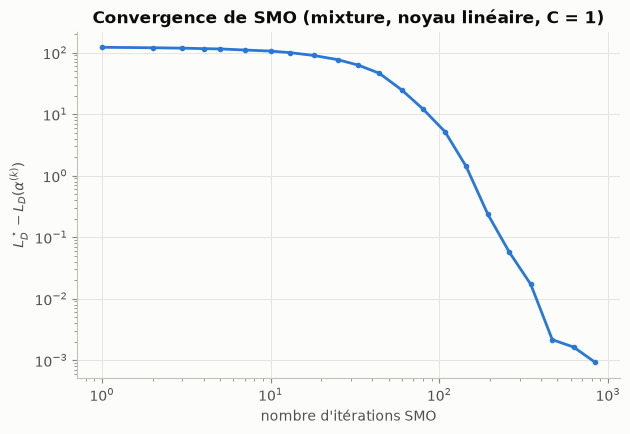

In [11]:
iters = np.unique(np.logspace(0, np.log10(it_smo), 25).astype(int))
vals = [dual(smo_solve(Q, -np.ones(len(y)), y, C, tol=1e-6, max_iter=k)[0]) for k in iters]
fig, ax = plt.subplots(figsize=(7, 4.5))
gap = dual(a_ip) - np.array(vals)
keep = gap > 1e-9
ax.semilogx(iters[keep], gap[keep], color=BLUE, marker="o", ms=3)
ax.set_yscale("log")
ax.set_xlabel("nombre d'itérations SMO"); ax.set_ylabel(r"$L_D^\star - L_D(\alpha^{(k)})$")
ax.set_title("Convergence de SMO (mixture, noyau linéaire, C = 1)")
plt.show()